<a href="https://colab.research.google.com/github/Vidharshh/artificial_intelligence_journey/blob/main/machine_learninglinear_lasso_ridge_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regression Models - Linear, lasso, ridge regression

**## Some of the important regression models**

| Order | Model | What makes it important? |
|---|---|---|
| 1 | **Linear Regression** | The foundation of regression and predictive modeling |
| 2 | **Ridge Regression (L2)** | Reduces overfitting through regularization |
| 3 | **Lasso Regression (L1)** | Regularization that can eliminate less useful features |
| 4 | **Multiple Linear Regression** | Predicts outcomes using multiple input features |
| 5 | **Polynomial Regression** | Models nonlinear relationships using polynomial features |
| 6 | **Decision Tree Regression** | Captures nonlinear patterns and decision-based relationships |
| 7 | **Random Forest Regression** | Combines multiple trees for more robust predictions |
| 8 | **Gradient Boosting Regression** | Builds models sequentially to correct previous errors |

## Linear regression

Linear Regression is a supervised machine learning algorithm that predicts a continuous numerical value by modeling a linear relationship between input features and an output.

| House Area (sq. ft.) | Price (₹ lakh) |
|---:|---:|
| 500 | 20 |
| 1,000 | 40 |
| 1,500 | 60 |
| 2,000 | 80 |

As the area increases, the price increases proportionally in this simplified example.

Linear Regression attempts to learn this relationship from the data.

# y = mx + c

In practice, the model estimates the coefficients from the training data rather than having them specified beforehand. (m and c)

It learns the line that best fits the observed data according to its objective.

Ordinary Least Squares (OLS) chooses coefficients that minimize the sum of squared residuals.

A residual is the difference between the actual value and the predicted value

geeksforgeeks : https://www.geeksforgeeks.org/machine-learning/ml-linear-regression/$0


### The objective is to minimise the sum of the sqaured residuals

Note : Squaring the errors penalizes larger deviations more heavily and prevents positive and negative errors from simply cancelling each other out.

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 1. Sample dataset
# X = House area in square feet
# y = House price in lakhs

X = np.array([[500], [1000], [1500], [2000], [2500]])
y = np.array([25, 38, 65, 75, 110])

# 2. Create and train the model
model = LinearRegression()
model.fit(X, y)

# 3. Generate predictions for drawing the line
X_line = np.linspace(500, 2500, 100).reshape(-1, 1)
y_line = model.predict(X_line)

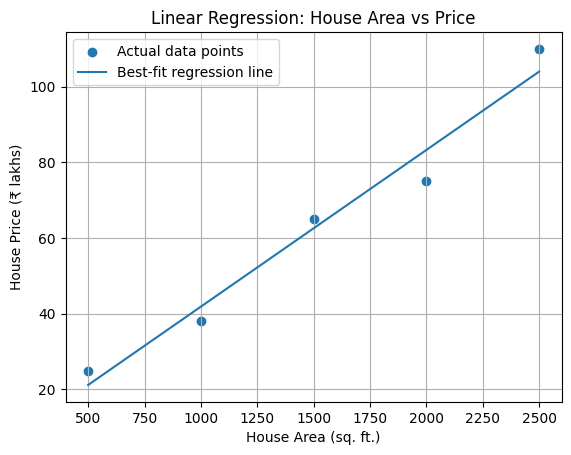

In [21]:

# 4. Plot actual data points (nodes)
plt.scatter(X, y, label="Actual data points")

# 5. Plot the regression line
plt.plot(X_line, y_line, label="Best-fit regression line")
# 6. Add labels and title
plt.xlabel("House Area (sq. ft.)")
plt.ylabel("House Price (₹ lakhs)")
plt.title("Linear Regression: House Area vs Price")
plt.legend()
plt.grid(True)

# 7. Display the plot
plt.show()

In [22]:

# 8. Print the learned equation
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)
print(f"Equation: Price = {model.intercept_:.2f} + {model.coef_[0]:.4f} × Area")


Slope: 0.041400000000000006
Intercept: 0.4999999999999929
Equation: Price = 0.50 + 0.0414 × Area


In [23]:
# 9. Predict the price of a 1750 sq. ft. house
prediction = model.predict([[1750]])
print(f"Predicted price for 1750 sq. ft.: ₹{prediction[0]:.2f} lakhs")

Predicted price for 1750 sq. ft.: ₹72.95 lakhs


### When should we use Linear Regression?
Use it when:
- You want to predict a continuous numerical outcome.
- The relationship between features and the target is reasonably linear.
- You need a simple, interpretable baseline model.
- You want to understand how input features relate to the prediction.
Examples:
- Sales forecasting.
- Price prediction.
- Demand estimation.
- Cost estimation.
### Limitations
- It may perform poorly when relationships are strongly nonlinear.
- Outliers can significantly affect the fitted model.
- Multicollinearity can make individual coefficients unstable.
- It cannot establish causation simply because two variables are correlated.

## Regularised regression models

There are some regularization techniques that modify the training objective to discourage overly large coefficients.

#### Problem 1: Overfitting
Suppose your model learns very large coefficients because it tries too hard to fit the training data.
It might perform extremely well on training data but poorly on new, unseen houses.

This is called overfitting.

#### Problem 2: Multicollinearity
Suppose your dataset contains both:
- Number of bedrooms
- Total number of rooms
These features might be strongly correlated.

When features are highly correlated, Linear Regression can struggle to estimate their individual effects reliably. Small changes in the data might cause their coefficients to change substantially.


#### Problem 3: Too many features
Suppose you're using 100 features, but only 10 meaningfully contribute to predicting the house price.

You might want to reduce the influence of unnecessary features.
#### This is where Ridge and Lasso come in!

Compare the penalties:
- Ridge: squares the coefficients.
- Lasso: takes the absolute values of the coefficients.
This difference changes how the optimization behaves. Lasso can drive coefficients exactly to zero, whereas Ridge generally shrinks them without eliminating them.

When should you use Ridge?
Use Ridge when:
- You have many features.
- Features are strongly correlated.
- You want to reduce overfitting.
- You believe several features contribute useful information and want to retain them.
Interview takeaway: Ridge uses an L2 penalty and shrinks coefficients toward zero without generally eliminating features.

When should you use Lasso?
Use Lasso when:
- You have many features.
- You suspect some features contribute little.
- You want a simpler, more interpretable model.
- Feature selection is useful.
One caution: when features are strongly correlated, Lasso may select one and eliminate others somewhat arbitrarily. Its selected features aren't automatically the only genuinely important ones.
Interview takeaway: Lasso uses an L1 penalty and can shrink some coefficients exactly to zero, effectively performing feature selection.

### What happens when lambda changes?

| Lambda (\(\lambda\)) | Effect |
|---|---|
| 0 | Equivalent to ordinary Linear Regression, assuming the same setup |
| Small | Mild coefficient shrinkage |
| Large | Stronger coefficient shrinkage |
| Extremely large | Coefficients approach zero, potentially causing underfitting |

In [37]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 1. Dataset
# House area in square feet
X = np.array([
    [500], [800], [1000], [1200], [1500],
    [1800], [2000], [2200], [2500], [2800]
])

# House prices in lakhs
y = np.array([20, 32, 40, 48, 60, 72, 80, 88, 100, 112])


In [42]:
# 2. Create models
linear = LinearRegression()

ridge = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1)
)

lasso = make_pipeline(
    StandardScaler(),
    Lasso(alpha=10, max_iter=10000)
)

# 3. Train the models
linear.fit(X, y)
ridge.fit(X, y)
lasso.fit(X, y)


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('lasso', Lasso(alpha=10, max_iter=10000))])

In [43]:
# 4. Generate X values for smooth lines
X_line = np.linspace(500, 2800, 200).reshape(-1, 1)

# 5. Predict prices
y_linear = linear.predict(X_line)
y_ridge = ridge.predict(X_line)
y_lasso = lasso.predict(X_line)


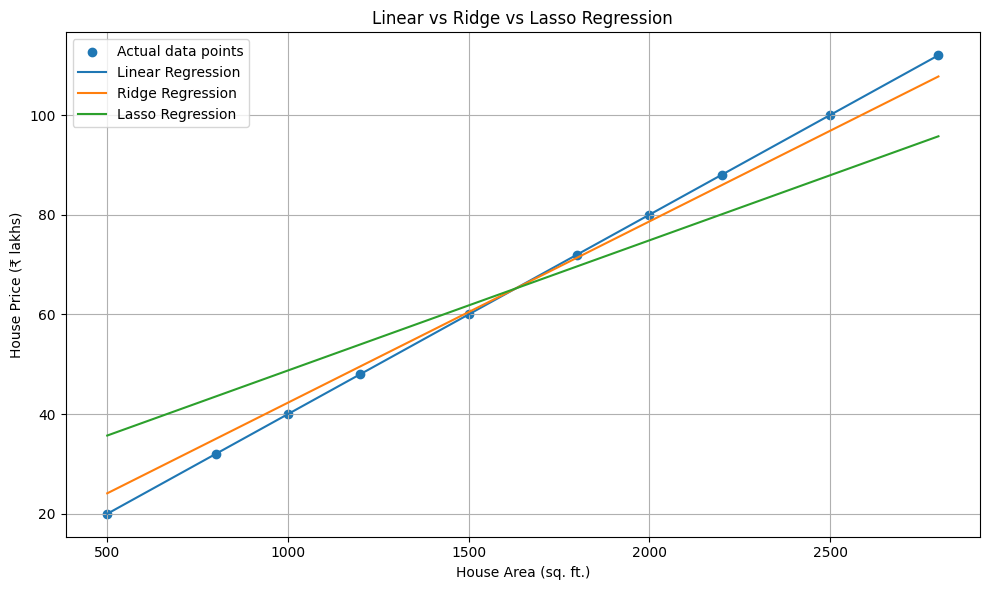

In [44]:
# 6. Plot everything together
plt.figure(figsize=(10, 6))

# Actual data points
plt.scatter(X.ravel(), y, label="Actual data points")

# Regression lines
plt.plot(X_line.ravel(), y_linear, label="Linear Regression")
plt.plot(X_line.ravel(), y_ridge, label="Ridge Regression")
plt.plot(X_line.ravel(), y_lasso, label="Lasso Regression")

# Labels and formatting
plt.xlabel("House Area (sq. ft.)")
plt.ylabel("House Price (₹ lakhs)")
plt.title("Linear vs Ridge vs Lasso Regression")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [45]:
# 7. Compare coefficients
print("Linear coefficient:", linear.coef_[0])

print(
    "Ridge coefficient:",
    ridge.named_steps["ridge"].coef_[0]
)

print(
    "Lasso coefficient:",
    lasso.named_steps["lasso"].coef_[0]
)

Linear coefficient: 0.039999999999999994
Ridge coefficient: 26.174241327895437
Lasso coefficient: 18.791665460684975
